# Practical 6 (Mini-Project) — Titanic Survival Prediction

**Subject:** Machine Learning (410242)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)  
**Mini-project option:** B — Predicting Titanic survival from passenger data

---

## 1. Aim

Build and compare machine-learning classifiers that predict whether a Titanic
passenger survived, using passenger information such as name, age, sex,
ticket class and family details.

## 2. Problem statement

The sinking of the RMS Titanic is a well-known binary-classification problem.
Each row describes one passenger. The target is

$$y=\begin{cases}1,&\text{the passenger survived},\\0,&\text{the passenger died}.\end{cases}$$

Using the labelled Kaggle training set (891 passengers), we will:

1. explore the data and identify missing values,
2. engineer useful features from names, family information and cabin data,
3. build preprocessing and classification pipelines,
4. compare Logistic Regression, Random Forest and Gradient Boosting,
5. evaluate the models with accuracy, precision, recall, F1 and ROC-AUC.

## 3. Dataset

**Titanic — Machine Learning from Disaster** — Kaggle:  
<https://www.kaggle.com/competitions/titanic/data>

The file `data/titanic.csv.gz` is the labelled `train.csv` from the
competition. It contains 891 passengers and 12 columns:

| Column | Meaning |
|---|---|
| `PassengerId` | Identifier (not a feature) |
| `Survived` | Target: 0 = died, 1 = survived |
| `Pclass` | Ticket class: 1 = first, 2 = second, 3 = third |
| `Name` | Passenger name, including title and family name |
| `Sex` | `male` or `female` |
| `Age` | Age in years (177 missing) |
| `SibSp` | Number of siblings/spouses aboard |
| `Parch` | Number of parents/children aboard |
| `Ticket` | Ticket number |
| `Fare` | Passenger fare |
| `Cabin` | Cabin number (687 missing) |
| `Embarked` | Port: C = Cherbourg, Q = Queenstown, S = Southampton (2 missing) |

The competition's `test.csv` has no public labels, so a stratified holdout
from the labelled data is used for the final evaluation.

## 4. Objectives

- Perform exploratory data analysis on a real, imperfect dataset.
- Handle missing values without leaking information from the test set.
- Engineer interpretable features: passenger title, family size, travelling
  alone, known cabin and log fare.
- Build leakage-free `Pipeline` objects with a `ColumnTransformer`.
- Tune and compare three classifiers using stratified cross-validation.
- Interpret the results and explain which passenger groups had higher
  predicted survival.

## 5. Theory

### 5.1 Binary classification

A classifier learns a function $f:\mathbb{R}^d\to\{0,1\}$ from training pairs
$(x_i,y_i)$. For a probabilistic classifier, the output is

$$\hat{p}_i=P(y_i=1\mid x_i),$$

and the default decision rule is

$$\hat{y}_i=\begin{cases}1,&\hat{p}_i\ge 0.5,\\0,&\hat{p}_i<0.5.\end{cases}$$

The Titanic target is imbalanced (about 38% survived), so accuracy alone is
not enough. We also report precision, recall, F1 and ROC-AUC.

### 5.2 Logistic Regression

Logistic Regression models the log-odds as a linear function of the features:

$$\log\frac{p}{1-p}=w\cdot x+b,
\qquad p=\sigma(w\cdot x+b)=\frac{1}{1+e^{-(w\cdot x+b)}}.$$

It is trained by minimising the binary cross-entropy (log loss)

$$J(w,b)=-\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\log\hat{p}_i+(1-y_i)\log(1-\hat{p}_i)\right]
+\frac{1}{2C}\|w\|^2.$$

The L2 penalty controlled by $C$ reduces overfitting. Logistic Regression is a
strong, interpretable baseline for tabular data.

### 5.3 Decision trees and Random Forest

A decision tree recursively splits the feature space to make the child nodes
purer. A common impurity measure is the Gini index:

$$G=1-\sum_{k}p_k^2.$$

A single tree is easy to interpret but has high variance. **Random Forest**
builds many decorrelated trees on bootstrap samples and random feature
subsets, then averages their probabilities:

$$\hat{p}(x)=\frac{1}{T}\sum_{t=1}^{T}\hat{p}_t(x).$$

Averaging reduces variance and usually improves generalisation.

### 5.4 Gradient Boosting

Gradient Boosting builds trees **sequentially**, where each new tree fits the
negative gradient (the residual) of the current loss. With a small learning
rate $\nu$, the prediction is updated as

$$F_t(x)=F_{t-1}(x)+\nu\,h_t(x).$$

Boosting has low bias but can overfit if there are too many trees or if the
trees are too deep, so `n_estimators`, `learning_rate` and `max_depth` are
tuned.

### 5.5 Feature engineering

- **Title** extracted from `Name` summarises sex, age and social status
  (`Mr`, `Mrs`, `Miss`, `Master`, and rare titles).
- **FamilySize** $=$ `SibSp` + `Parch` + 1.
- **IsAlone** indicates a family size of one.
- **HasCabin** uses the fact that a recorded cabin is itself informative.
- **FareLog** $=\log(1+\text{Fare})$ reduces the strong right skew of fare.
- **AgeMissing** preserves the information that age was not recorded.

All imputation and scaling are fitted **inside** the training pipeline, so the
test set never influences the learned medians, modes or scales.

### 5.6 Evaluation metrics

With survival as the positive class:

$$\text{Precision}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN},\qquad
F_1=2\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}.$$

- **Accuracy:** overall fraction correct; misleading when classes are
  imbalanced.
- **Precision:** of the passengers predicted to survive, how many did?
- **Recall:** of the passengers who survived, how many were found?
- **F1:** harmonic mean of precision and recall.
- **ROC-AUC:** probability that a random survivor is ranked above a random
  non-survivor; 0.5 is random and 1.0 is perfect.

Cross-validation gives a more stable estimate than a single train/test split.
We use **stratified 5-fold CV**, which preserves the survival proportion in
every fold.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("ML/data")

RANDOM_STATE = 42

In [2]:
df = pd.read_csv(DATA_DIR / "titanic.csv.gz")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
df.head()

Dataset shape: (891, 12)

First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Data audit: types, missing values and cardinality.
audit = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing %": (100 * df.isna().mean()).round(1),
        "unique values": df.nunique(),
    }
)
audit

,dtype,missing,missing %,unique values
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


## 6. Exploratory data analysis

Before modelling, we check the target balance and the relationship between
survival and the most important available variables.

Survival counts:
Survived
Died        549
Survived    342
Name: count, dtype: int64

Survival rate: 0.3838


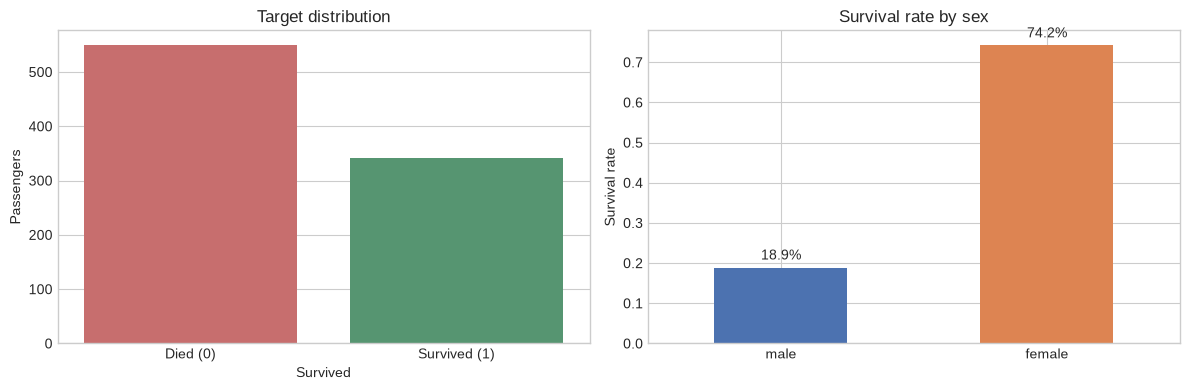

In [4]:
print("Survival counts:")
print(df["Survived"].value_counts().rename({0: "Died", 1: "Survived"}))
print("\nSurvival rate:", round(df["Survived"].mean(), 4))

figure, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="Survived",
    hue="Survived",
    palette=["#d65f5f", "#4c9f70"],
    legend=False,
    ax=axes[0],
)
axes[0].set_xticks([0, 1], ["Died (0)", "Survived (1)"])
axes[0].set_title("Target distribution")
axes[0].set_ylabel("Passengers")

survival_by_sex = df.groupby("Sex")["Survived"].mean().sort_values()
survival_by_sex.plot(kind="bar", color=["#4c72b0", "#dd8452"], ax=axes[1])
axes[1].set_title("Survival rate by sex")
axes[1].set_ylabel("Survival rate")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
for index, value in enumerate(survival_by_sex):
    axes[1].text(index, value + 0.02, f"{value:.1%}", ha="center")

plt.tight_layout()
plt.show()

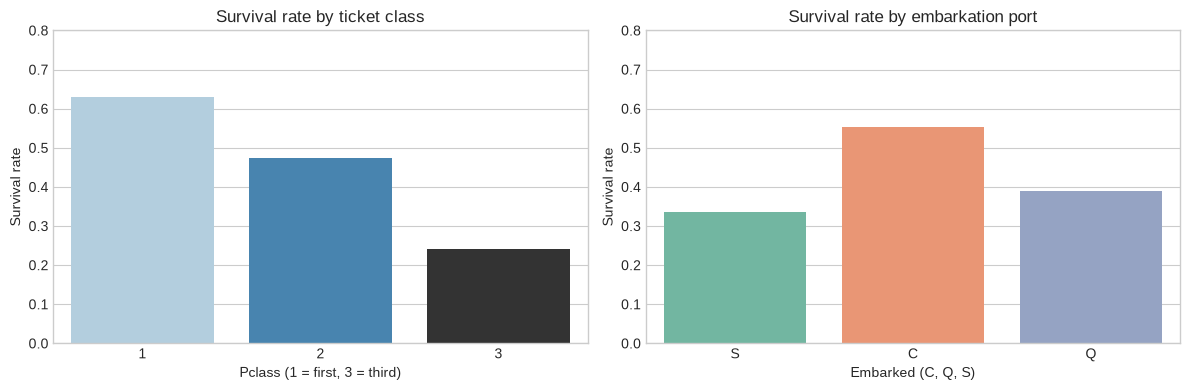

In [5]:
# Survival by class and port of embarkation.
figure, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Pclass",
    palette="Blues_d",
    errorbar=None,
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Survival rate by ticket class")
axes[0].set_xlabel("Pclass (1 = first, 3 = third)")
axes[0].set_ylabel("Survival rate")
axes[0].set_ylim(0, 0.8)

sns.barplot(
    data=df,
    x="Embarked",
    y="Survived",
    hue="Embarked",
    palette="Set2",
    errorbar=None,
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Survival rate by embarkation port")
axes[1].set_xlabel("Embarked (C, Q, S)")
axes[1].set_ylabel("Survival rate")
axes[1].set_ylim(0, 0.8)

plt.tight_layout()
plt.show()

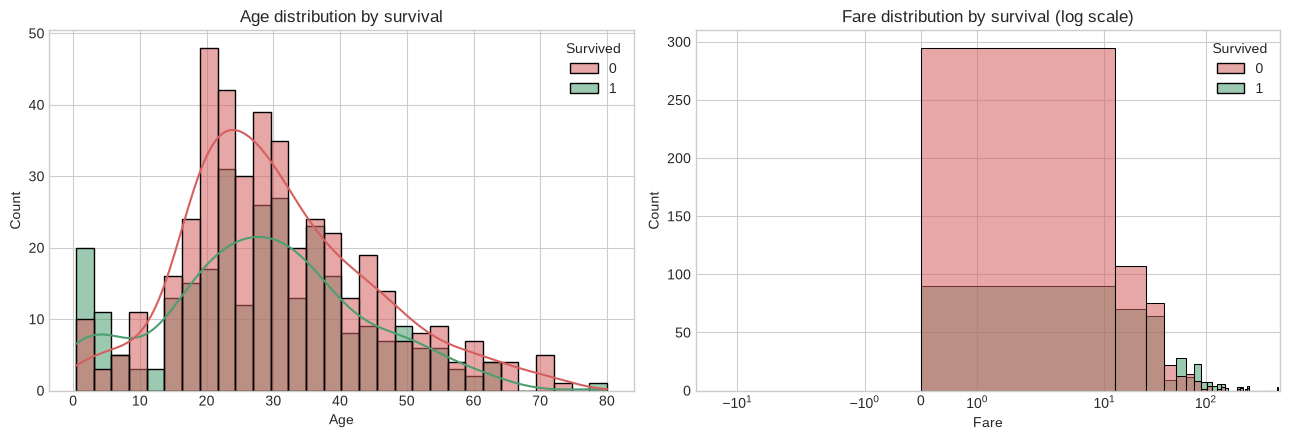

In [6]:
# Age and fare distributions split by survival.
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    palette=["#d65f5f", "#4c9f70"],
    alpha=0.55,
    ax=axes[0],
)
axes[0].set_title("Age distribution by survival")
axes[0].set_xlabel("Age")

sns.histplot(
    data=df,
    x="Fare",
    hue="Survived",
    bins=40,
    palette=["#d65f5f", "#4c9f70"],
    alpha=0.55,
    ax=axes[1],
)
axes[1].set_xscale("symlog")
axes[1].set_title("Fare distribution by survival (log scale)")
axes[1].set_xlabel("Fare")

plt.tight_layout()
plt.show()

**Initial observations.**

- Only about 38% of passengers survived, so the classes are moderately
  imbalanced.
- Women survived at a much higher rate than men, consistent with the
  "women and children first" evacuation policy.
- First-class passengers survived more often than third-class passengers.
- Survivors tend to have paid higher fares, and the fare distribution is
  strongly right-skewed.
- Age is missing for many passengers, so an explicit missing-value indicator
  is useful.

## 7. Feature engineering

We extract titles from names, create family features, mark whether a cabin is
known, and apply a log transform to fare. These transformations use only the
passenger's own row (except title grouping, which is a fixed, target-free
mapping), so they do not leak the test labels.

In [7]:
title_map = {
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs",
    "Lady": "Mrs",
    "The Countess": "Mrs",
    "Don": "Rare",
    "Sir": "Rare",
    "Capt": "Rare",
    "Col": "Rare",
    "Major": "Rare",
    "Rev": "Rare",
    "Dr": "Rare",
    "Jonkheer": "Rare",
}


def engineer_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Create model-ready features without using the target."""
    data = frame.copy()

    # Titles: Mr, Mrs, Miss, Master and a pooled Rare category.
    data["Title"] = (
        data["Name"]
        .str.extract(r",\s*([^.]+)\.", expand=False)
        .str.strip()
        .str.title()
        .replace(title_map)
    )

    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
    data["HasCabin"] = data["Cabin"].notna().astype(int)
    data["AgeMissing"] = data["Age"].isna().astype(int)
    data["FareLog"] = np.log1p(data["Fare"])

    return data


df_model = engineer_features(df)

print("Title counts:")
print(df_model["Title"].value_counts().to_string())
print("\nFamily-size counts:")
print(df_model["FamilySize"].value_counts().sort_index().to_string())
print("\nMissing values in engineered columns:")
print(
    df_model[["Title", "FamilySize", "HasCabin", "AgeMissing", "FareLog"]]
    .isna()
    .sum()
    .to_string()
)
df_model[["Name", "Title", "FamilySize", "IsAlone", "HasCabin", "FareLog"]].head()

Title counts:
Title
Mr        517
Miss      185
Mrs       128
Master     40
Rare       21

Family-size counts:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7

Missing values in engineered columns:
Title         0
FamilySize    0
HasCabin      0
AgeMissing    0
FareLog       0


,Name,Title,FamilySize,IsAlone,HasCabin,FareLog
0,"Braund, Mr. Owen Harris",Mr,2,0,0,2.110213
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,1,4.280593
2,"Heikkinen, Miss. Laina",Miss,1,1,0,2.188856
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,1,3.990834
4,"Allen, Mr. William Henry",Mr,1,1,0,2.202765


In [8]:
# Family size has a non-linear relationship with survival: very large families
# had low survival rates. This motivates keeping FamilySize as a feature.
family_summary = (
    df_model.groupby("FamilySize")["Survived"]
    .agg(passengers="size", survival_rate="mean")
    .reset_index()
)
family_summary["survival_rate"] = family_summary["survival_rate"].round(3)
family_summary

,FamilySize,passengers,survival_rate
0,1,537,0.304
1,2,161,0.553
2,3,102,0.578
3,4,29,0.724
4,5,15,0.200
5,6,22,0.136
6,7,12,0.333
7,8,6,0.000
8,11,7,0.000


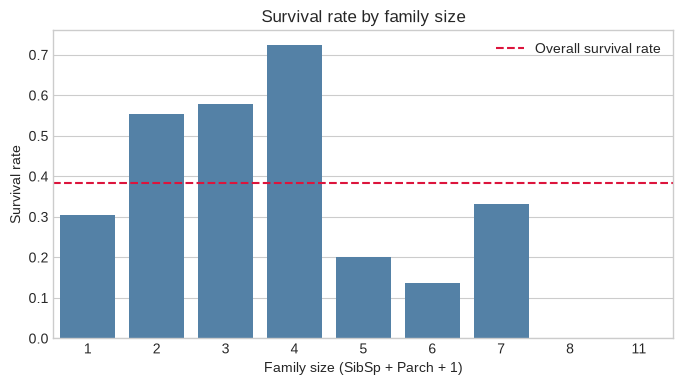

In [9]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=family_summary,
    x="FamilySize",
    y="survival_rate",
    color="steelblue",
)
plt.axhline(
    df["Survived"].mean(),
    color="crimson",
    linestyle="--",
    label="Overall survival rate",
)
plt.xlabel("Family size (SibSp + Parch + 1)")
plt.ylabel("Survival rate")
plt.title("Survival rate by family size")
plt.legend()
plt.show()

## 8. Train/test split and preprocessing

We use a stratified 80/20 split. The preprocessing object is fitted only on
the training data:

- numeric features: median imputation, then standardisation;
- categorical features: most-frequent imputation, then one-hot encoding.

Wrapping everything in a `Pipeline` prevents accidental leakage during
cross-validation.

In [10]:
numeric_features = [
    "Pclass",
    "Age",
    "FareLog",
    "FamilySize",
    "IsAlone",
    "HasCabin",
    "AgeMissing",
]
categorical_features = ["Sex", "Embarked", "Title"]
feature_columns = numeric_features + categorical_features

X = df_model[feature_columns]
y = df_model["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

print("Training rows:", len(X_train))
print("Test rows    :", len(X_test))
print("Training survival rate:", round(y_train.mean(), 3))
print("Test survival rate    :", round(y_test.mean(), 3))

Training rows: 712
Test rows    : 179
Training survival rate: 0.383
Test survival rate    : 0.385


## 9. Baseline model

A `DummyClassifier` always predicts the majority class. Any useful model must
beat this baseline; otherwise the features add no value.

In [11]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline F1      :", round(f1_score(y_test, baseline_pred), 4))
print("\nBaseline confusion matrix:")
print(confusion_matrix(y_test, baseline_pred))

Baseline accuracy: 0.6145
Baseline F1      : 0.0

Baseline confusion matrix:
[[110   0]
 [ 69   0]]


## 10. Model training and hyperparameter tuning

Each model is tuned with 5-fold stratified cross-validation on the **training
set** only. The test set is kept untouched until the final comparison.

- Logistic Regression: tune the inverse regularisation strength $C$.
- Random Forest: tune the number of trees, maximum depth and minimum leaf
  size.
- Gradient Boosting: tune the number of trees, learning rate and depth.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Logistic Regression.
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE),
        ),
    ]
)

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid={"classifier__C": [0.01, 0.1, 1.0, 10.0]},
    scoring="roc_auc",
    cv=cv,
    refit=True,
)
logistic_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:", logistic_search.best_params_)
print("Best CV ROC-AUC:", round(logistic_search.best_score_, 4))

Best Logistic Regression parameters: {'classifier__C': 10.0}
Best CV ROC-AUC: 0.874


In [13]:
# Random Forest.
forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

forest_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid={
        "classifier__n_estimators": [300, 500],
        "classifier__max_depth": [4, 6, None],
        "classifier__min_samples_leaf": [1, 3],
    },
    scoring="roc_auc",
    cv=cv,
    refit=True,
)
forest_search.fit(X_train, y_train)

print("Best Random Forest parameters:", forest_search.best_params_)
print("Best CV ROC-AUC:", round(forest_search.best_score_, 4))

Best Random Forest parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 300}
Best CV ROC-AUC: 0.8859


In [14]:
# Gradient Boosting.
boosting_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "classifier",
            GradientBoostingClassifier(random_state=RANDOM_STATE),
        ),
    ]
)

boosting_search = GridSearchCV(
    estimator=boosting_pipeline,
    param_grid={
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.03, 0.1],
        "classifier__max_depth": [2, 3],
    },
    scoring="roc_auc",
    cv=cv,
    refit=True,
)
boosting_search.fit(X_train, y_train)

print("Best Gradient Boosting parameters:", boosting_search.best_params_)
print("Best CV ROC-AUC:", round(boosting_search.best_score_, 4))

Best Gradient Boosting parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Best CV ROC-AUC: 0.8975


## 11. Final comparison on the held-out test set

The tuned models are now evaluated once on the 179 passengers in the test set.
The cross-validation score is also shown so that we can see whether the
holdout result is consistent with the training-time estimate.

In [15]:
def evaluate_classifier(name, model, cv_mean=np.nan, cv_std=np.nan):
    """Return one row of test-set metrics for a fitted classifier."""
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "CV ROC-AUC": cv_mean,
        "CV std": cv_std,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }


fitted_models = {
    "Logistic Regression": logistic_search.best_estimator_,
    "Random Forest": forest_search.best_estimator_,
    "Gradient Boosting": boosting_search.best_estimator_,
}

comparison_rows = [
    evaluate_classifier("Baseline (majority)", baseline),
    evaluate_classifier(
        "Logistic Regression",
        fitted_models["Logistic Regression"],
        logistic_search.best_score_,
        logistic_search.cv_results_["std_test_score"][logistic_search.best_index_],
    ),
    evaluate_classifier(
        "Random Forest",
        fitted_models["Random Forest"],
        forest_search.best_score_,
        forest_search.cv_results_["std_test_score"][forest_search.best_index_],
    ),
    evaluate_classifier(
        "Gradient Boosting",
        fitted_models["Gradient Boosting"],
        boosting_search.best_score_,
        boosting_search.cv_results_["std_test_score"][boosting_search.best_index_],
    ),
]

comparison = pd.DataFrame(comparison_rows).set_index("Model")
comparison.round(4).sort_values("ROC-AUC", ascending=False)

,CV ROC-AUC,CV std,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
Logistic Regression,0.8740,0.0203,0.8324,0.7910,0.7681,0.7794,0.8681
Random Forest,0.8859,0.0264,0.7877,0.7627,0.6522,0.7031,0.8490
Gradient Boosting,0.8975,0.0151,0.7989,0.7538,0.7101,0.7313,0.8300
Baseline (majority),NaN,NaN,0.6145,0.0000,0.0000,0.0000,0.5000


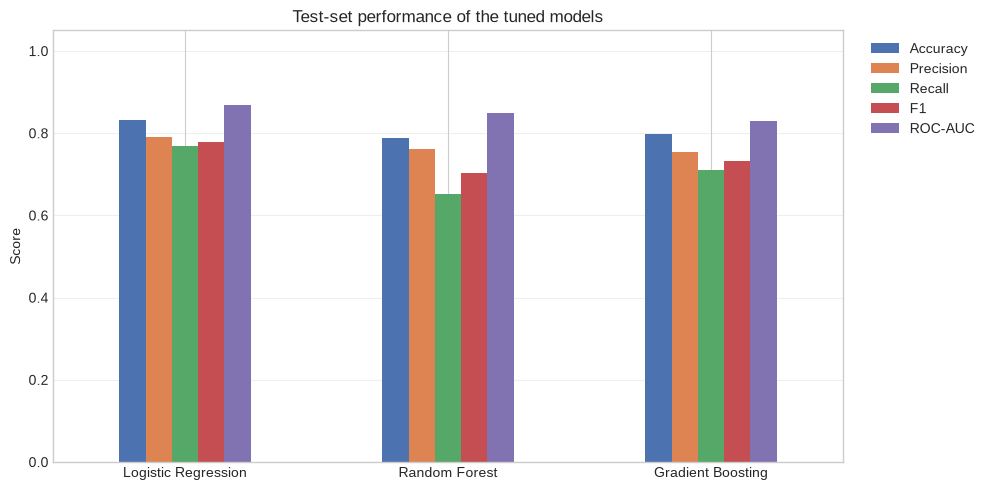

In [16]:
# Visual comparison of the four metrics.
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
learned_models = comparison.drop(index="Baseline (majority)")

figure, axis = plt.subplots(figsize=(10, 5))
learned_models[metrics_to_plot].plot(
    kind="bar",
    ax=axis,
    color=["#4c72b0", "#dd8452", "#55a868", "#c44e52", "#8172b2"],
)
axis.set_title("Test-set performance of the tuned models")
axis.set_ylabel("Score")
axis.set_ylim(0, 1.05)
axis.set_xlabel("")
axis.tick_params(axis="x", rotation=0)
axis.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Confusion matrices

A confusion matrix shows the actual and predicted classes. False negatives
are survivors predicted to have died; false positives are passengers
predicted to survive who actually died.

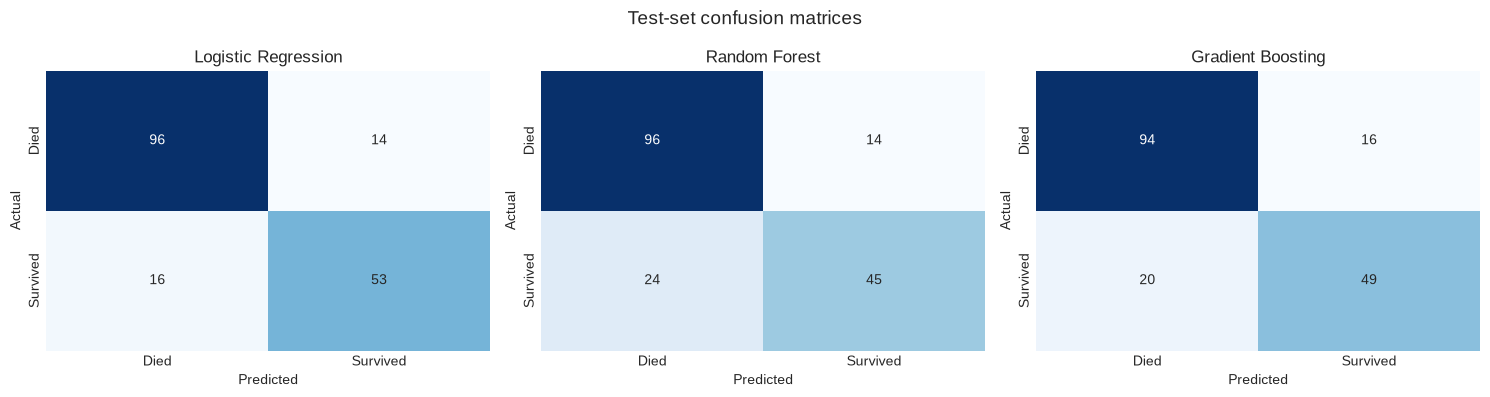

In [17]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (name, model) in zip(axes, fitted_models.items()):
    predictions = model.predict(X_test)
    matrix = confusion_matrix(y_test, predictions)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Died", "Survived"],
        yticklabels=["Died", "Survived"],
        ax=axis,
    )
    axis.set_title(name)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

plt.suptitle("Test-set confusion matrices", fontsize=14)
plt.tight_layout()
plt.show()

In [18]:
# Select the model by cross-validation, not by the test set. The test set is
# used only for the final, unbiased evaluation.
best_model_name = learned_models["CV ROC-AUC"].idxmax()
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Model selected by highest CV ROC-AUC:", best_model_name)
print("\nClassification report:")
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Died", "Survived"],
        digits=4,
        zero_division=0,
    )
)

Model selected by highest CV ROC-AUC: Gradient Boosting

Classification report:
              precision    recall  f1-score   support

        Died     0.8246    0.8545    0.8393       110
    Survived     0.7538    0.7101    0.7313        69

    accuracy                         0.7989       179
   macro avg     0.7892    0.7823    0.7853       179
weighted avg     0.7973    0.7989    0.7977       179



## 13. ROC curves

The ROC curve plots the true-positive rate against the false-positive rate as
the decision threshold varies. A curve closer to the top-left corner is
better; the area under the curve summarises this across all thresholds.

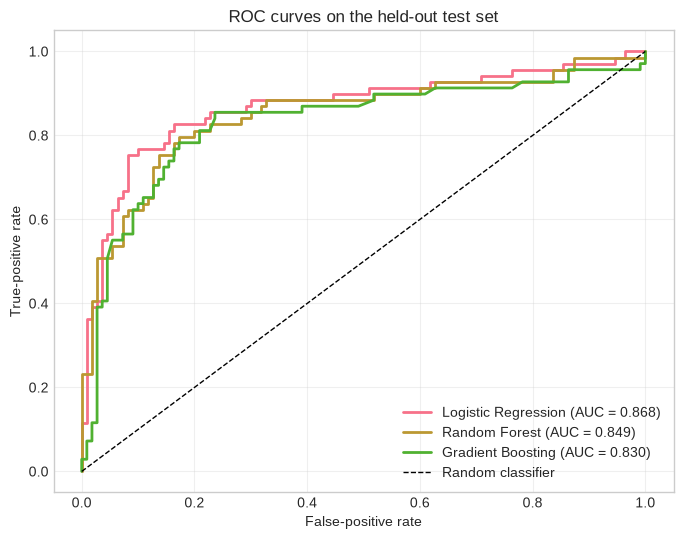

In [19]:
plt.figure(figsize=(8, 6))

for name, model in fitted_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test, probabilities
    )
    area = roc_auc_score(y_test, probabilities)
    plt.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{name} (AUC = {area:.3f})",
    )

plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random classifier")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("ROC curves on the held-out test set")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

## 14. Model interpretation

Random Forest provides a directly readable impurity-based feature importance.
One-hot features are shown with their original prefix; the importance of a
category is the reduction in impurity contributed by splits on that category.

Feature importance describes the model's use of a feature, **not** a causal
effect on survival.

In [20]:
best_forest = fitted_models["Random Forest"]
feature_names = best_forest.named_steps["preprocessor"].get_feature_names_out()
importances = best_forest.named_steps["classifier"].feature_importances_

importance_table = (
    pd.DataFrame(
        {
            "feature": [name.split("__", 1)[1] for name in feature_names],
            "importance": importances,
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
importance_table["importance"] = importance_table["importance"].round(4)
importance_table.head(15)

,feature,importance
0,FareLog,0.1535
1,Title_Mr,0.1495
2,Sex_male,0.1398
3,Age,0.1146
4,Sex_female,0.1104
5,Pclass,0.0832
6,FamilySize,0.0621
7,HasCabin,0.0559
8,Title_Mrs,0.0350
9,Title_Miss,0.0311


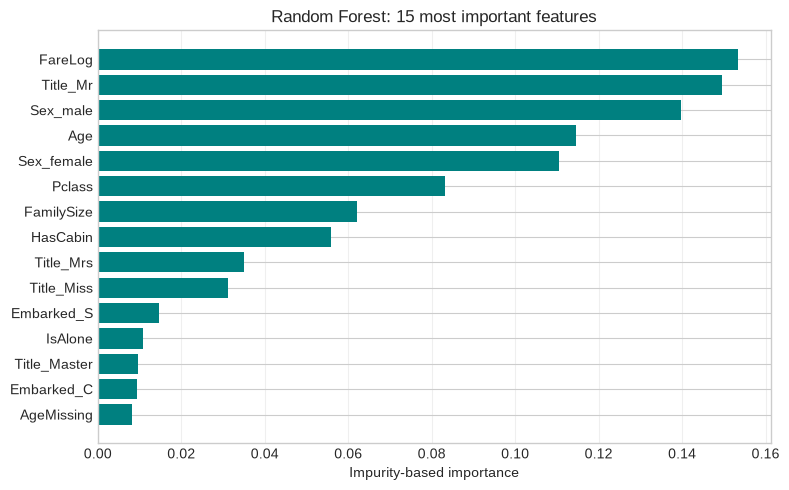

In [21]:
top_features = importance_table.head(15).sort_values("importance")
plt.figure(figsize=(8, 5))
plt.barh(top_features["feature"], top_features["importance"], color="teal")
plt.xlabel("Impurity-based importance")
plt.title("Random Forest: 15 most important features")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Error analysis

We inspect the passengers that the selected model got wrong. This is useful
for finding systematic weaknesses, such as a particular sex, class or age
group.

In [22]:
test_view = df.loc[X_test.index, ["Name", "Sex", "Pclass", "Age", "Fare"]].copy()
test_view["Actual"] = y_test.map({0: "Died", 1: "Survived"})
test_view["Predicted"] = pd.Series(best_predictions, index=X_test.index).map(
    {0: "Died", 1: "Survived"}
)
test_view["Survival probability"] = best_model.predict_proba(X_test)[:, 1]
test_view["Correct"] = test_view["Actual"] == test_view["Predicted"]

print("Test accuracy:", round(test_view["Correct"].mean(), 4))
print("\nError rate by sex:")
print(
    test_view.groupby("Sex")["Correct"]
    .agg(passengers="size", accuracy="mean")
    .assign(error_rate=lambda table: 1 - table["accuracy"])
    .round(3)
    .to_string()
)
print("\nError rate by passenger class:")
print(
    test_view.groupby("Pclass")["Correct"]
    .agg(passengers="size", accuracy="mean")
    .assign(error_rate=lambda table: 1 - table["accuracy"])
    .round(3)
    .to_string()
)

Test accuracy: 0.7989

Error rate by sex:
        passengers  accuracy  error_rate
Sex                                     
female          61     0.836       0.164
male           118     0.780       0.220

Error rate by passenger class:
        passengers  accuracy  error_rate
Pclass                                  
1               45     0.667       0.333
2               34     0.882       0.118
3              100     0.830       0.170


In [23]:
# Show the most confident mistakes first.
mistakes = test_view[~test_view["Correct"]].copy()
mistakes["confidence"] = (mistakes["Survival probability"] - 0.5).abs()
mistakes.sort_values("confidence", ascending=False).head(10)

,Name,Sex,Pclass,Age,Fare,Actual,Predicted,Survival probability,Correct,confidence
271,"Tornquist, Mr. William Henry",male,3,25.0,0.0000,Survived,Died,0.014603,False,0.485397
804,"Hedman, Mr. Oskar Arvid",male,3,27.0,6.9750,Survived,Died,0.014603,False,0.485397
570,"Harris, Mr. George",male,2,62.0,10.5000,Survived,Died,0.021924,False,0.478076
297,"Allison, Miss. Helen Loraine",female,1,2.0,151.5500,Died,Survived,0.973852,False,0.473852
245,"Minahan, Dr. William Edward",male,1,44.0,90.0000,Died,Survived,0.959949,False,0.459949
536,"Butt, Major. Archibald Willingham",male,1,45.0,26.5500,Died,Survived,0.942106,False,0.442106
444,"Johannesen-Bratthammer, Mr. Bernt",male,3,NaN,8.1125,Survived,Died,0.066267,False,0.433733
587,"Frolicher-Stehli, Mr. Maxmillian",male,1,60.0,79.2000,Survived,Died,0.071640,False,0.428360
17,"Williams, Mr. Charles Eugene",male,2,NaN,13.0000,Survived,Died,0.086852,False,0.413148
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,3,27.0,7.7958,Survived,Died,0.101452,False,0.398548


## 16. Validation and sanity checks

The following checks confirm that the pipeline is fitted, the predictions are
valid probabilities, and the best learned model beats the majority baseline.

In [24]:
best_probabilities = best_model.predict_proba(X_test)[:, 1]
best_predictions = best_model.predict(X_test)

assert len(best_predictions) == len(y_test)
assert np.all((best_probabilities >= 0) & (best_probabilities <= 1))
assert np.all(np.isin(best_predictions, [0, 1]))
assert best_model.score(X_test, y_test) > baseline.score(X_test, y_test)
assert comparison.loc[best_model_name, "ROC-AUC"] > 0.5

print("All validation checks passed ✓")
print("Selected learned model:", best_model_name)
print("Test accuracy     :", round(accuracy_score(y_test, best_predictions), 4))
print("Test ROC-AUC      :", round(roc_auc_score(y_test, best_probabilities), 4))

All validation checks passed ✓
Selected learned model: Gradient Boosting
Test accuracy     : 0.7989
Test ROC-AUC      : 0.83


In [25]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - ML Practical 6 (Titanic survival)")
print("=" * 78)
print(
    "The target is binary: 1 means the passenger survived. The report connects\n"
    "the exploratory statistics, the cross-validation scores, the holdout\n"
    "scores and the confusion matrix. The test set is small, so differences of\n"
    "one or two passengers are not strong evidence of a better model."
)

print("\n1. DATA AUDIT AND CLASS BALANCE")
print("-" * 78)
print(f"Rows                    : {len(df):,}")
print(f"Columns                 : {df.shape[1]}")
print(f"Survivors               : {int(df['Survived'].sum()):,}")
print(f"Deaths                  : {int((df['Survived'] == 0).sum()):,}")
print(f"Survival rate           : {df['Survived'].mean():.2%}")
print(f"Missing Age             : {int(df['Age'].isna().sum()):,}")
print(f"Missing Cabin           : {int(df['Cabin'].isna().sum()):,}")
print(f"Missing Embarked        : {int(df['Embarked'].isna().sum()):,}")
print(f"Training rows           : {len(X_train):,}")
print(f"Test rows               : {len(X_test):,}")
print(f"Test survival rate      : {y_test.mean():.2%}")
print("The classes are moderately imbalanced: about 38% survived. A model that")
print("always predicts 'died' would already be about 62% accurate, so accuracy")
print("alone is not a useful measure of success.")

print("\n2. SURVIVAL PATTERNS IN THE DATA")
print("-" * 78)
survival_by_sex = df.groupby("Sex")["Survived"].mean().sort_values(ascending=False)
for sex, rate in survival_by_sex.items():
    print(f"  {sex:6s}: {rate:.2%} survival")
survival_by_class = df.groupby("Pclass")["Survived"].mean().sort_values(ascending=False)
for passenger_class, rate in survival_by_class.items():
    print(f"  Pclass {int(passenger_class)}: {rate:.2%} survival")
print("Titles (engineered from Name):")
for title, count in df_model["Title"].value_counts().head(8).items():
    print(f"  {title:8s}: {count}")
print("These are associations in this historical sample, not causal effects.")
print("Women and first-class passengers had much higher survival rates. The")
print("title feature summarises sex, age and social status in one column.")

print("\n3. FAMILY SIZE")
print("-" * 78)
for _, row in family_summary.iterrows():
    print(
        f"  FamilySize={int(row['FamilySize'])}: "
        f"passengers={int(row['passengers'])}, "
        f"survival={row['survival_rate']:.3f}"
    )
print("Survival is non-linear in family size: very large families had low")
print("survival, while small families often did better than solo travellers.")
print("This is why FamilySize is kept as a numeric feature rather than reduced")
print("to a simple 'alone' indicator.")

print("\n4. CROSS-VALIDATION AND HOLDOUT RESULTS")
print("-" * 78)
for model_name in comparison.index:
    row = comparison.loc[model_name]
    cv_text = "n/a" if pd.isna(row["CV ROC-AUC"]) else f"{row['CV ROC-AUC']:.4f}"
    print(
        f"  {model_name:22s}: CV AUC={cv_text}, "
        f"test acc={row['Accuracy']:.4f}, prec={row['Precision']:.4f}, "
        f"rec={row['Recall']:.4f}, F1={row['F1']:.4f}, "
        f"test AUC={row['ROC-AUC']:.4f}"
    )
selected_by_cv = comparison.loc[best_model_name]
best_test_name = (
    comparison.drop(index="Baseline (majority)")
    .sort_values("ROC-AUC", ascending=False)
    .index[0]
)
best_test = comparison.loc[best_test_name]
print(f"\nSelected by highest CV ROC-AUC: {best_model_name}")
print(
    f"  CV ROC-AUC={selected_by_cv['CV ROC-AUC']:.4f}, "
    f"test accuracy={selected_by_cv['Accuracy']:.4f}, "
    f"test F1={selected_by_cv['F1']:.4f}, "
    f"test ROC-AUC={selected_by_cv['ROC-AUC']:.4f}"
)
print(
    f"Best on the holdout by ROC-AUC: {best_test_name} "
    f"(AUC={best_test['ROC-AUC']:.4f}, accuracy={best_test['Accuracy']:.4f})"
)
print("The selection rule is important: choosing the model by its CV score")
print("keeps the test set unbiased. The holdout can still disagree because it")
print("contains only 179 passengers; one passenger changes accuracy by about")
print(f"{100 / len(y_test):.2f} percentage points.")

print("\n5. CONFUSION MATRIX OF THE SELECTED MODEL")
print("-" * 78)
selected_matrix = confusion_matrix(y_test, best_predictions)
tn, fp, fn, tp = selected_matrix.ravel()
print(f"  TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("TP: survivors correctly identified; TN: deaths correctly identified.")
print("FP: predicted survival but died; FN: predicted death but survived.")
print("Recall = TP/(TP+FN) is the fraction of survivors found. Precision =")
print("TP/(TP+FP) is the fraction of predicted survivors who really survived.")
print("In a safety or rescue context, recall is often the more important of the")
print("two, but the cost of false alarms should decide the threshold.")

print("\n6. FEATURE IMPORTANCE")
print("-" * 78)
for _, row in importance_table.head(10).iterrows():
    print(f"  {row['feature']:18s}: {row['importance']:.4f}")
print("These are impurity-based importances from the Random Forest. Sex, title,")
print("fare and class dominate because they encode the strongest survival")
print("patterns. Importance means the model used the feature; it does not mean")
print("the feature caused survival. Correlated features share importance, so the")
print("ranking should not be read as a set of independent effects.")

print("\n7. ERROR ANALYSIS")
print("-" * 78)
print(f"Overall test accuracy: {test_view['Correct'].mean():.4f}")
print("Error rate by sex:")
sex_errors = (
    test_view.groupby("Sex")["Correct"]
    .agg(passengers="size", accuracy="mean")
    .assign(error_rate=lambda table: 1 - table["accuracy"])
)
print(sex_errors.round(3).to_string())
print("Error rate by passenger class:")
class_errors = (
    test_view.groupby("Pclass")["Correct"]
    .agg(passengers="size", accuracy="mean")
    .assign(error_rate=lambda table: 1 - table["accuracy"])
)
print(class_errors.round(3).to_string())
print("A higher error rate for a group does not automatically mean the model is")
print("unfair; the group may be smaller or intrinsically harder to classify.")
print("The table is a diagnostic starting point, not a fairness proof.")

print("\n8. HYPERPARAMETERS SELECTED")
print("-" * 78)
print("Logistic Regression:", logistic_search.best_params_)
print("Random Forest     :", forest_search.best_params_)
print("Gradient Boosting :", boosting_search.best_params_)
print("The grids were searched with stratified 5-fold CV on the training set.")
print("GridSearchCV refits the best configuration on the full training set, and")
print("that fitted pipeline is what produced the holdout predictions.")

print("\n9. TAKEAWAY")
print("-" * 78)
print("All learned models beat the majority-class baseline, so the features carry")
print("real signal. Sex, class, fare and family structure are the main patterns.")
print("Use CV for model selection, report precision/recall/F1 as well as")
print("accuracy, and remember that a single small holdout is noisy. The model's")
print("associations are historical, not causal, and should not be used to make")
print("decisions about individuals.")

DETAILED OUTPUT EXPLANATION - ML Practical 6 (Titanic survival)
The target is binary: 1 means the passenger survived. The report connects
the exploratory statistics, the cross-validation scores, the holdout
scores and the confusion matrix. The test set is small, so differences of
one or two passengers are not strong evidence of a better model.

1. DATA AUDIT AND CLASS BALANCE
------------------------------------------------------------------------------
Rows                    : 891
Columns                 : 12
Survivors               : 342
Deaths                  : 549
Survival rate           : 38.38%
Missing Age             : 177
Missing Cabin           : 687
Missing Embarked        : 2
Training rows           : 712
Test rows               : 179
Test survival rate      : 38.55%
The classes are moderately imbalanced: about 38% survived. A model that
always predicts 'died' would already be about 62% accurate, so accuracy
alone is not a useful measure of success.

2. SURVIVAL PATTERNS I

## 17. Observations

1. **Sex is the strongest signal.** Women survived at roughly 74%, compared
   with about 19% for men. The model therefore learns a large sex effect,
   which is consistent with the historical evacuation policy.
2. **Passenger class and fare matter.** First-class passengers had a much
   higher survival rate than third-class passengers, and higher fares are
   associated with survival. Class and fare are correlated, so their
   importance should not be interpreted as independent causal effects.
3. **Family size is non-linear.** Passengers travelling in small families
   (2–4 people) survived more often than those travelling alone or in very
   large families.
4. **Missingness is informative.** A missing age or cabin is not random:
   cabin records are available mainly for higher-class passengers. The
   `HasCabin` and `AgeMissing` indicators let the model use this information
   without pretending the values are known.
5. **All learned models beat the baseline.** The baseline predicts "died"
   for everyone and has an accuracy equal to the majority-class proportion,
   but its recall and F1 for survivors are zero.
6. **The test set is small, so scores move visibly.** It contains only 179
   passengers, so one extra correct prediction changes accuracy by about 0.56
   percentage points. Logistic Regression generalised best on this particular
   holdout, while Gradient Boosting had the highest cross-validation ROC-AUC.
   This is a reminder that model selection should use cross-validation and
   that a single holdout split has sampling noise.
7. **ROC-AUC is more informative than accuracy** here. A model can achieve
   decent accuracy by favouring the majority class while missing many
   survivors. Precision, recall and F1 expose that trade-off.
8. **Feature importance is not causation.** The model describes associations
   in this historical sample; it does not prove that a feature caused
   survival.

## 18. Complexity analysis

Let $n$ be the number of training rows, $d$ the number of encoded features,
$T$ the number of trees and $k$ the number of folds.

| Model | Training cost | Prediction cost | Main hyperparameters |
|---|---|---|---|
| Logistic Regression | $O(n d)$ per iteration | $O(d)$ per sample | $C$, max iterations |
| Random Forest | $O(T n \log n)$ | $O(T \cdot \text{depth})$ per sample | trees, depth, leaf size |
| Gradient Boosting | $O(T n \log n)$ | $O(T \cdot \text{depth})$ per sample | trees, learning rate, depth |
| Grid search | $O(k \cdot \text{number of configurations})$ fits | — | grid size |

The preprocessing step is linear in the number of rows. One-hot encoding adds
only a small number of columns because the categorical variables have low
cardinality. For this dataset ($n=712$ training rows), all three searches run
comfortably on a laptop CPU.

## 19. Conclusion

We built an end-to-end Titanic survival classifier from raw passenger records.
After exploring the data, we engineered title, family-size, cabin-availability
and fare features, and wrapped imputation, scaling and one-hot encoding inside
leakage-free pipelines. Logistic Regression, Random Forest and Gradient
Boosting were tuned with stratified 5-fold cross-validation and compared on a
held-out test set using accuracy, precision, recall, F1 and ROC-AUC.

All learned models clearly outperformed the majority-class baseline. The
results confirm the historical pattern that sex, passenger class and fare were
strongly associated with survival, while family size had a non-linear effect.
The project also shows why accuracy alone is insufficient for an imbalanced
classification problem, and why proper validation, preprocessing pipelines and
error analysis are essential parts of a machine-learning workflow.

**Limitations.** The dataset is small and observational. The 891 labelled
passengers are not a random sample of all passengers, the test set is a
holdout from the same source rather than the competition's unlabelled test
set, and the model's associations should not be read as causal effects.

## 20. Viva questions

| Question | Short answer |
|---|---|
| What type of machine-learning problem is Titanic survival prediction? | Supervised binary classification. |
| Why is accuracy not sufficient here? | The classes are imbalanced, so a majority-class predictor can have high accuracy but zero recall for survivors. |
| What is the difference between precision and recall? | Precision measures how many predicted survivors actually survived; recall measures how many actual survivors were found. |
| What does ROC-AUC measure? | The probability that a random positive example is ranked above a random negative example. |
| Why use a stratified train/test split? | It preserves the class proportion in both sets, giving a more representative evaluation. |
| Why must imputation be inside a pipeline? | To fit medians/modes on training data only and avoid test-set leakage during cross-validation. |
| Why one-hot encode categorical variables? | Models need numeric inputs, and one-hot encoding avoids imposing a false ordinal relationship. |
| Why use a log transform for fare? | Fare is strongly right-skewed; the log transform reduces the influence of extreme values. |
| What is the purpose of the `HasCabin` feature? | The presence of a cabin record is informative even when the cabin number itself is missing. |
| What is the difference between Random Forest and Gradient Boosting? | Random Forest averages many independent trees; Gradient Boosting adds trees sequentially to correct previous errors. |
| What does feature importance mean? | How much a model used a feature to reduce impurity; it is not a causal effect. |
| What is overfitting? | Learning training-specific noise so that performance on unseen data is worse. |
| How can overfitting be reduced? | Regularisation, pruning/depth limits, more data, cross-validation and simpler models. |
| What is data leakage? | Using information from outside the training data (especially the test set or target) during training. |
| Why is a baseline model useful? | It gives the minimum performance that a useful model must beat. |